# Cannabis consumption: data preparation

We first look at the dataset, check for problems and prepare the inputs for our models. We group the original cannabis responses into three classes:

| Class | Meaning | Original codes |
|---|---|---|
| 0 | Never used | CL0 |
| 1 | Former user: last used more than one year ago | CL1, CL2 |
| 2 | Recent user: used within the last year | CL3, CL4, CL5, CL6 |

The aim is to predict these groups using demographic information and personality scores.

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile
import hashlib
import json
import platform
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Find the data whether we run from the project folder or notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW = ROOT / "data/raw/drug_consumption.data"
OUT = ROOT / "data/processed"
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
for folder in (RAW.parent, OUT, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)
SEED = 42
TEST_SIZE = 0.20
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load the data

The data file has no headings, so we add the column names from the UCI documentation. We download it only if the local copy is missing. The checksum checks the file contents after normalising line endings.

In [2]:
URL = "https://archive.ics.uci.edu/static/public/373/drug%2Bconsumption%2Bquantified.zip"
EXPECTED_SHA256 = "90b8cf500b07ad455baf9fe1dc519998c75a1df6d87f6bd7069176f0826ea8c1"
if not RAW.exists():
    with urlopen(URL, timeout=60) as response:
        archive = ZipFile(BytesIO(response.read()))
    RAW.write_bytes(archive.read("drug_consumption.data"))

# Normalise line endings before checking the original file.
raw_hash = hashlib.sha256(RAW.read_bytes().replace(b"\r\n", b"\n").replace(b"\n", b"\r\n")).hexdigest()
assert raw_hash == EXPECTED_SHA256, "Source changed; review it before proceeding."

FEATURES = ["age", "gender", "education", "country", "ethnicity", "nscore", "escore",
            "oscore", "ascore", "cscore", "impulsive", "ss"]
DRUGS = ["alcohol", "amphet", "amyl", "benzos", "caff", "cannabis", "choc", "coke",
         "crack", "ecstasy", "heroin", "ketamine", "legalh", "lsd", "meth",
         "mushrooms", "nicotine", "semer", "vsa"]
raw = pd.read_csv(RAW, header=None, names=["id"] + FEATURES + DRUGS)
assert raw.shape == (1885, 32)
print(f"Raw data: {len(raw):,} respondents, {raw.shape[1]} columns")
display(raw.head())

Raw data: 1,885 respondents, 32 columns


,id,age,gender,education,country,ethnicity,nscore,escore,oscore,ascore,...,ecstasy,heroin,ketamine,legalh,lsd,meth,mushrooms,nicotine,semer,vsa
0,1,0.49788,0.48246,-0.05921,0.96082,0.12600,0.31287,-0.57545,-0.58331,-0.91699,...,CL0,CL0,CL0,CL0,CL0,CL0,CL0,CL2,CL0,CL0
1,2,-0.07854,-0.48246,1.98437,0.96082,-0.31685,-0.67825,1.93886,1.43533,0.76096,...,CL4,CL0,CL2,CL0,CL2,CL3,CL0,CL4,CL0,CL0
2,3,0.49788,-0.48246,-0.05921,0.96082,-0.31685,-0.46725,0.80523,-0.84732,-1.62090,...,CL0,CL0,CL0,CL0,CL0,CL0,CL1,CL0,CL0,CL0
3,4,-0.95197,0.48246,1.16365,0.96082,-0.31685,-0.14882,-0.80615,-0.01928,0.59042,...,CL0,CL0,CL2,CL0,CL0,CL0,CL0,CL2,CL0,CL0
4,5,0.49788,0.48246,1.98437,0.96082,-0.31685,0.73545,-1.63340,-0.45174,-0.30172,...,CL1,CL0,CL0,CL1,CL0,CL0,CL2,CL2,CL0,CL0


## 2. Understand the columns

We use 12 inputs: five demographic attributes and seven personality or behavioural scores. We use the cannabis response as the target. IDs and all substance-use columns are excluded from the inputs.

| Inputs | Meaning |
|---|---|
| age, education | Age groups and education levels, stored as quantified scores |
| gender, country, ethnicity | Demographic categories, stored as numeric codes |
| nscore, escore, oscore | Neuroticism, extraversion and openness |
| ascore, cscore | Agreeableness and conscientiousness |
| impulsive, ss | Impulsivity and sensation seeking |

The consumption codes describe when someone last used a substance: CL0 means never, CL1 over a decade ago, CL2 within the last decade, CL3 within the last year, CL4 within the last month, CL5 within the last week and CL6 within the last day. They do not tell us how much someone used.

Negative values come from UCI's conversion of the responses into numeric scores. Age represents a band rather than an exact age. The lookup tables below decode the demographic categories. In the drug columns, `meth` means methadone.

In [3]:
MAPS = {
    "age": {-0.95197: "18-24", -0.07854: "25-34", 0.49788: "35-44",
            1.09449: "45-54", 1.82213: "55-64", 2.59171: "65+"},
    "gender": {0.48246: "Female", -0.48246: "Male"},
    "education": {-2.43591: "Left before 16", -1.73790: "Left at 16", -1.43719: "Left at 17",
                  -1.22751: "Left at 18", -0.61113: "Some college, no degree",
                  -0.05921: "Professional certificate/diploma", 0.45468: "University degree",
                  1.16365: "Masters degree", 1.98437: "Doctorate"},
    "country": {-0.09765: "Australia", 0.24923: "Canada", -0.46841: "New Zealand",
                -0.28519: "Other", 0.21128: "Republic of Ireland", 0.96082: "UK", -0.57009: "USA"},
    "ethnicity": {-0.50212: "Asian", -1.10702: "Black", 1.90725: "Mixed-Black/Asian",
                  0.12600: "Mixed-White/Asian", -0.22166: "Mixed-White/Black",
                  0.11440: "Other", -0.31685: "White"},
}
RECENCY = {"CL0": "Never", "CL1": "Over a decade ago", "CL2": "Last decade",
           "CL3": "Last year", "CL4": "Last month", "CL5": "Last week", "CL6": "Last day"}
TARGET_MAP = {"CL0": 0, "CL1": 1, "CL2": 1, "CL3": 2, "CL4": 2, "CL5": 2, "CL6": 2}
CLASS_NAMES = {0: "Never used", 1: "Former user", 2: "Recent user"}
TARGET = "cannabis_class"

# Save the column meanings for reference.
descriptions = ["Reference ID", "Quantified age band", "Gender", "Quantified education",
                "Country of residence", "Ethnicity", "Neuroticism", "Extraversion",
                "Openness", "Agreeableness", "Conscientiousness", "Impulsivity", "Sensation seeking"]
dictionary = pd.DataFrame({"column": list(raw.columns) + [TARGET],
    "role": ["reference"] + ["predictor"] * 12 + ["response; excluded from X"] * 19 + ["target"],
    "meaning": descriptions + [f"{d} recency CL0-CL6" for d in DRUGS] + ["0=never, 1=former, 2=recent"]})
dictionary.loc[dictionary.column == "meth", "meaning"] = "Methadone recency"
dictionary.loc[dictionary.column == "semer", "meaning"] = "Fictitious Semeron quality check"
dictionary.to_csv(REPORTS / "data_dictionary.csv", index=False)
display(dictionary)

,column,role,meaning
0,id,reference,Reference ID
1,age,predictor,Quantified age band
2,gender,predictor,Gender
3,education,predictor,Quantified education
4,country,predictor,Country of residence
5,ethnicity,predictor,Ethnicity
6,nscore,predictor,Neuroticism
7,escore,predictor,Extraversion
8,oscore,predictor,Openness
9,ascore,predictor,Agreeableness


## 3. Check and clean the data

We found no missing values, repeated IDs, invalid codes or infinite values. We also checked for duplicate responses without using the ID and found none.

Eight respondents reported using Semeron, a fictitious drug. We remove these responses and save their IDs in `excluded_respondents.csv`. This leaves 1,877 respondents.

We keep extreme personality scores because a high or low score alone does not mean the response is wrong. No imputation was needed.

In [4]:
assert raw.isna().sum().sum() == 0, "Missing values require review."
assert raw.id.is_unique and pd.api.types.is_integer_dtype(raw.id)
assert np.isfinite(raw[["id"] + FEATURES].to_numpy(dtype=float)).all()
assert raw[DRUGS].isin(list(RECENCY)).all().all()
for column, mapping in MAPS.items():
    assert raw[column].round(5).isin(mapping).all(), f"Unknown code in {column}"

# Remove responses that claim use of the fictitious drug.
flagged = raw.semer.ne("CL0")
excluded = raw.loc[flagged, ["id", "semer"]].copy()
excluded["reason"] = "Reported fictitious Semeron use"
excluded.to_csv(REPORTS / "excluded_respondents.csv", index=False)
clean = raw.loc[~flagged].copy()
duplicates = clean.duplicated(subset=FEATURES + DRUGS)
duplicate_ids = clean.loc[duplicates, "id"].tolist()
clean = clean.loc[~duplicates].copy()
# Combine the seven cannabis codes into our three classes.
clean[TARGET] = clean.cannabis.map(TARGET_MAP).astype("int64")
quality = {"raw_rows": len(raw), "raw_columns": raw.shape[1], "missing_cells": int(raw.isna().sum().sum()),
           "duplicate_responses_raw": int(raw.duplicated(subset=FEATURES + DRUGS).sum()),
           "semeron_excluded": int(flagged.sum()), "duplicate_ids_removed": duplicate_ids,
           "clean_rows": len(clean)}
display(pd.Series(quality, name="value").to_frame())
clean.to_csv(OUT / "cleaned_data.csv", index=False)

,value
raw_rows,1885
raw_columns,32
missing_cells,0
duplicate_responses_raw,0
semeron_excluded,8
duplicate_ids_removed,[]
clean_rows,1877


## 4. Split into training and testing sets

We split the cleaned data into 1,501 training rows (80%) and 376 test rows (20%). We use `random_state=42` to make the split repeatable and `stratify=y` to keep similar class proportions in both sets.

We use the training set for exploration and fitting preprocessing. The test set is kept for the final evaluation.

In [5]:
indexed = clean.set_index("id", verify_integrity=True)
X, y = indexed[FEATURES].copy(), indexed[TARGET].copy()


# Check for identical input profiles before splitting people between the sets.
assert not X.duplicated().any(), "Repeated profiles: review grouped splitting."
X_train_q, X_test_q, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)
train = indexed.loc[X_train_q.index].copy()
print(f"Training: {len(y_train):,}; test: {len(y_test):,}")
membership = pd.DataFrame({"id": indexed.index})
membership["split"] = np.where(membership.id.isin(y_train.index), "train", "test")
membership.to_csv(OUT / "split_membership.csv", index=False)

Training: 1,501; test: 376


## 5. Explore the training data

We check class counts, demographic groups, score distributions and correlations using the training set. Recent users are the largest class, so accuracy alone could hide poor results for the smaller classes.

The plots are saved in `reports/figures/`. They describe the survey sample and do not establish causes of cannabis use.

,class,count,percent
0,Never used,330,21.99
1,Former user,378,25.18
2,Recent user,793,52.83


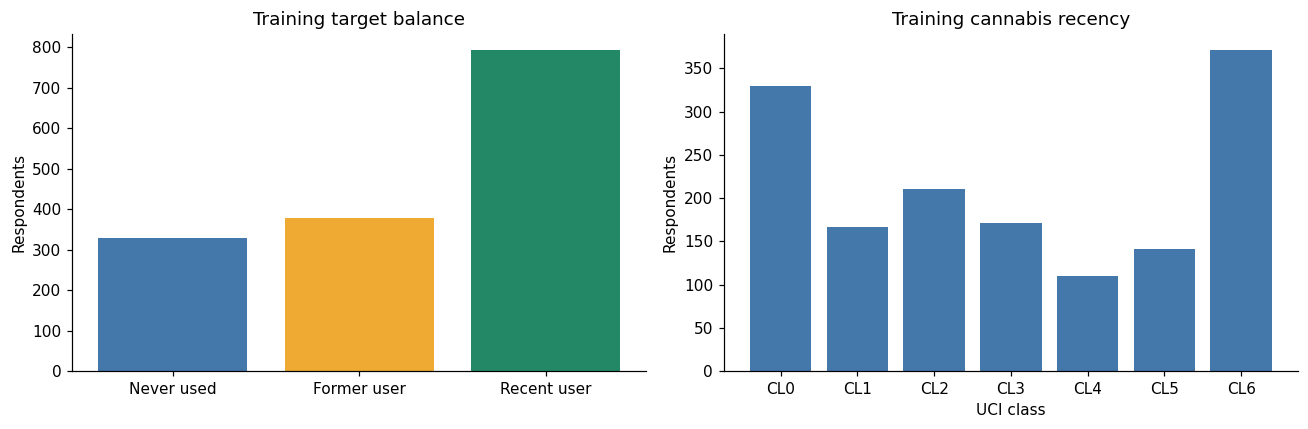

Largest/smallest training class ratio: 2.40
Later use macro-F1, per-class recall, and a confusion matrix alongside accuracy.


In [6]:
counts = y_train.value_counts().reindex(CLASS_NAMES, fill_value=0).sort_index()
balance = pd.DataFrame({"class": pd.Series(CLASS_NAMES), "count": counts,
                        "percent": (100 * counts / len(y_train)).round(2)})
display(balance)
balance.to_csv(REPORTS / "training_class_balance.csv", index_label="target")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(balance["class"], balance["count"], color=["#4477aa", "#eeaa33", "#228866"])
axes[0].set(title="Training target balance", ylabel="Respondents")
recency = train.cannabis.value_counts().reindex(RECENCY, fill_value=0)
axes[1].bar(recency.index, recency.values, color="#4477aa")
axes[1].set(title="Training cannabis recency", ylabel="Respondents", xlabel="UCI class")
fig.tight_layout()
fig.savefig(FIGURES / "training_class_balance.png", bbox_inches="tight")
plt.show()
print(f"Largest/smallest training class ratio: {counts.max()/counts.min():.2f}")
print("Later use macro-F1, per-class recall, and a confusion matrix alongside accuracy.")

,feature,category,count,percent
0,age,18-24,503,33.51
1,age,25-34,398,26.52
2,age,35-44,280,18.65
3,age,45-54,230,15.32
4,age,55-64,75,5.00
5,age,65+,15,1.00
6,gender,Male,758,50.50
7,gender,Female,743,49.50
8,education,"Some college, no degree",405,26.98
9,education,University degree,371,24.72


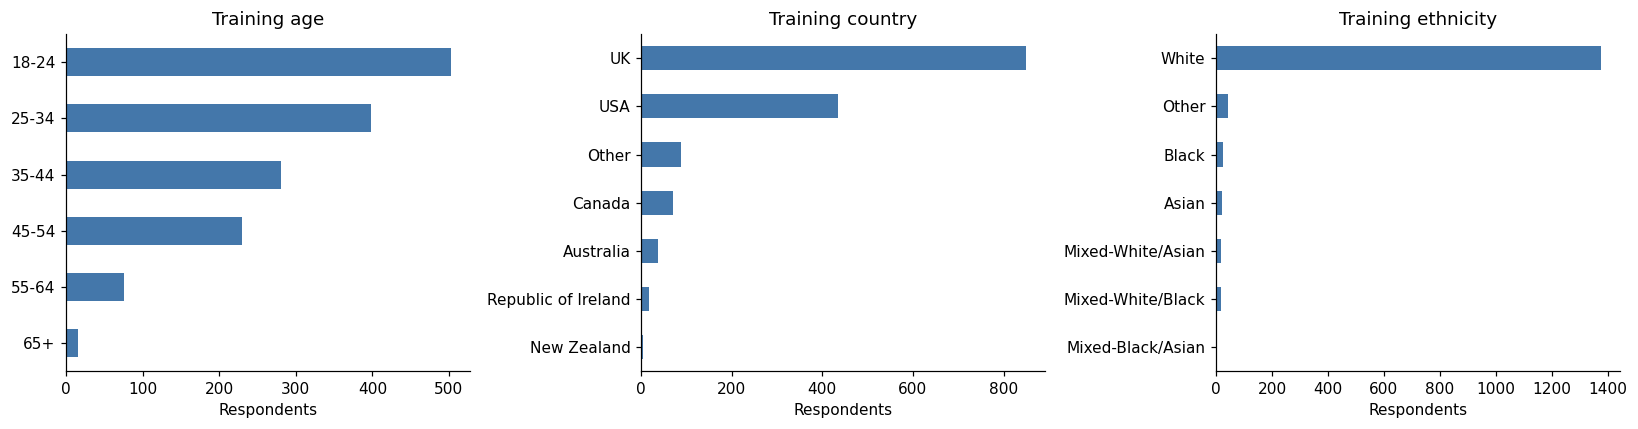

In [7]:
tables = []
for column, mapping in MAPS.items():
    freq = train[column].round(5).map(mapping).value_counts()
    tables.append(pd.DataFrame({"feature": column, "category": freq.index, "count": freq.values,
                               "percent": 100 * freq.values / len(train)}))
demographics = pd.concat(tables, ignore_index=True)
demographics.to_csv(REPORTS / "training_demographics.csv", index=False)
display(demographics.round(2))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ["age", "country", "ethnicity"]):
    train[column].round(5).map(MAPS[column]).value_counts().sort_values().plot.barh(ax=ax, color="#4477aa")
    ax.set(title=f"Training {column}", xlabel="Respondents", ylabel="")
fig.tight_layout()
fig.savefig(FIGURES / "training_demographics.png", bbox_inches="tight")
plt.show()

,count,mean,std,min,25%,50%,75%,max
age,1501.0,0.038,0.876,-0.952,-0.952,-0.079,0.498,2.592
gender,1501.0,-0.005,0.483,-0.482,-0.482,-0.482,0.482,0.482
education,1501.0,0.003,0.960,-2.436,-0.611,-0.059,0.455,1.984
country,1501.0,0.373,0.698,-0.570,-0.570,0.961,0.961,0.961
ethnicity,1501.0,-0.312,0.160,-1.107,-0.317,-0.317,-0.317,1.907
nscore,1501.0,-0.004,0.989,-3.464,-0.678,0.043,0.630,3.274
escore,1501.0,-0.013,1.005,-3.274,-0.695,0.003,0.638,3.274
oscore,1501.0,-0.012,0.997,-3.274,-0.717,-0.019,0.723,2.902
ascore,1501.0,-0.003,1.004,-3.464,-0.606,-0.017,0.590,3.157
cscore,1501.0,-0.017,1.012,-3.464,-0.653,-0.007,0.758,3.464


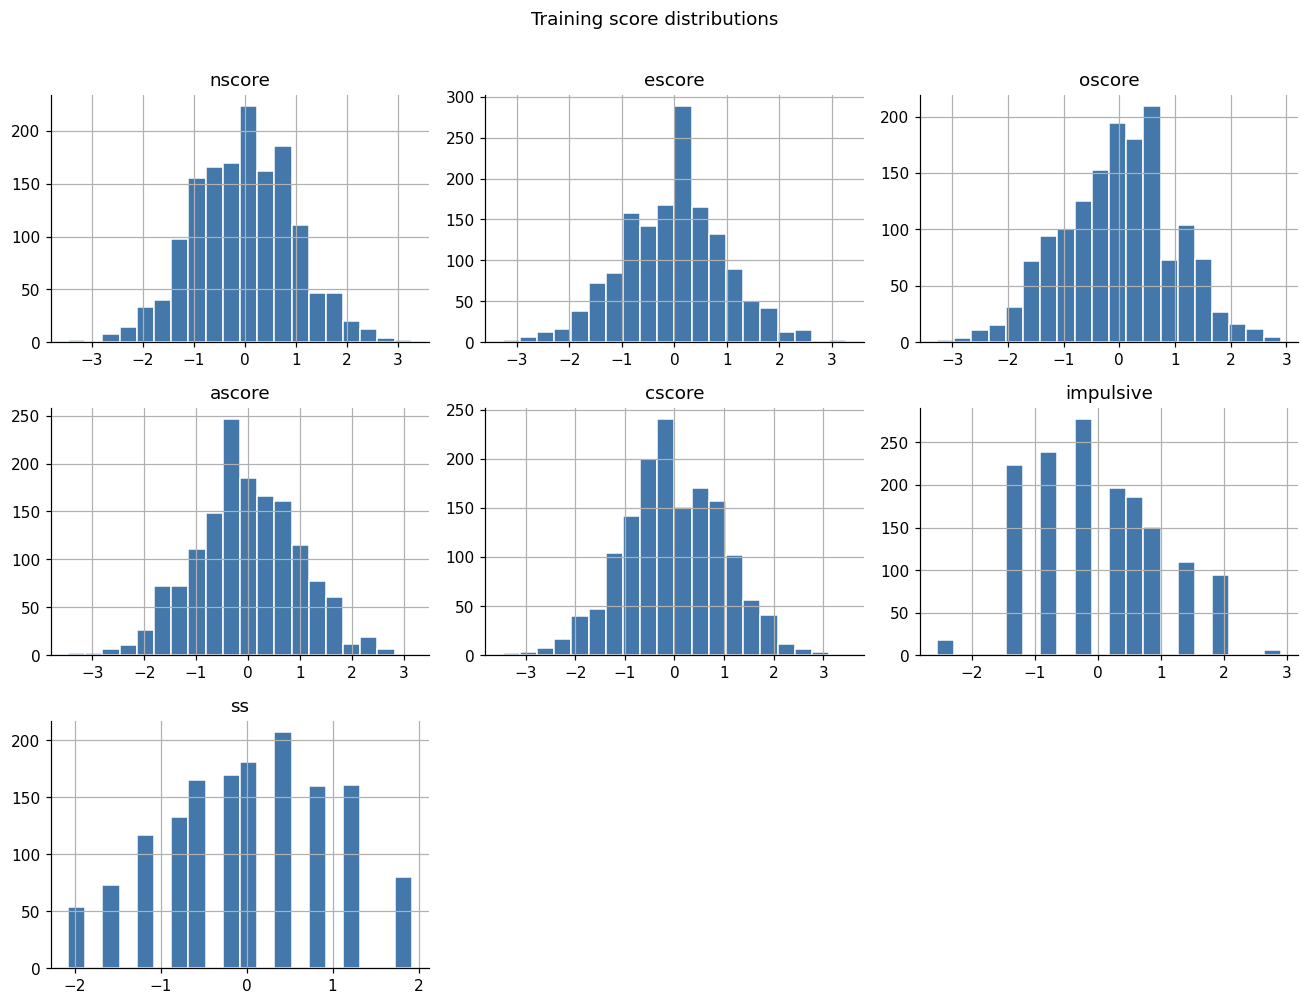

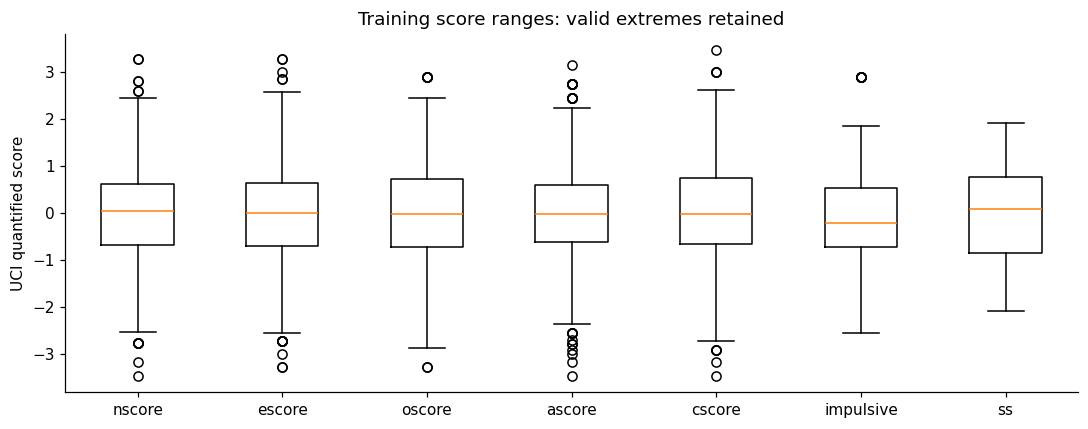

In [8]:
SCORES = ["nscore", "escore", "oscore", "ascore", "cscore", "impulsive", "ss"]
summary = train[FEATURES].describe().T
summary.to_csv(REPORTS / "training_numeric_summary.csv")
display(summary.round(3))
axes = train[SCORES].hist(bins=20, figsize=(12, 9), color="#4477aa", edgecolor="white")
fig = axes.ravel()[0].figure
fig.suptitle("Training score distributions", y=1.01)
fig.tight_layout()
fig.savefig(FIGURES / "training_score_distributions.png", bbox_inches="tight")
plt.show()
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([train[c].to_numpy() for c in SCORES], tick_labels=SCORES)
ax.set(title="Training score ranges: valid extremes retained", ylabel="UCI quantified score")
fig.tight_layout()
fig.savefig(FIGURES / "training_score_boxplots.png", bbox_inches="tight")
plt.show()

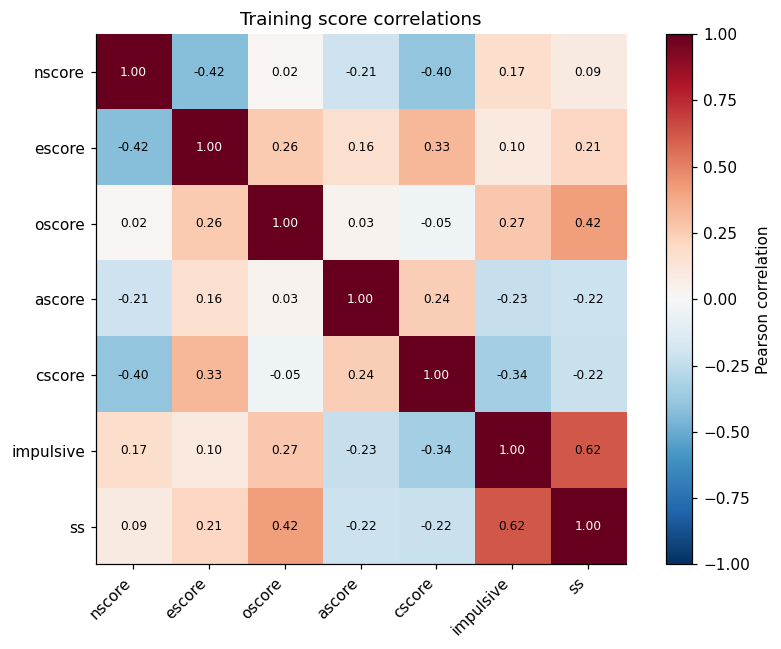

In [9]:

# Use the seven scores here; country codes are not meaningful numeric distances.
corr = train[SCORES].corr()
fig, ax = plt.subplots(figsize=(8, 6))
heatmap = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(SCORES)), SCORES, rotation=45, ha="right")
ax.set_yticks(range(len(SCORES)), SCORES)
for row in range(len(SCORES)):
    for col in range(len(SCORES)):
        value = corr.iloc[row, col]
        
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > 0.65 else "black")
ax.set_title("Training score correlations")
fig.colorbar(heatmap, ax=ax, label="Pearson correlation")
fig.tight_layout()
fig.savefig(FIGURES / "training_score_correlations.png", bbox_inches="tight")
plt.show()
corr.to_csv(REPORTS / "training_score_correlations.csv")

## 6. Encode and scale the inputs

Gender, country and ethnicity are categories even though the original file stores them as numbers. We one-hot encode them into 0/1 columns. For example, `country_UK` is 1 for UK respondents and 0 for everyone else. This avoids treating country codes as numeric distances.

We keep the supplied age and education scores and the seven personality and behavioural scores as numeric inputs. These nine columns are standardised using the training mean and standard deviation. The original UCI quantification was done before release, so we cannot refit that step.

We fit the encoder and scaler on the training set and use them to transform the test set. The result has 25 columns, including all one-hot columns. We save the fitted transformer and do not use oversampling or feature selection.

In [10]:
CATEGORICAL = ["gender", "country", "ethnicity"]
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]
def decode_nominal(frame):
    result = frame.copy()
    for column in CATEGORICAL:
        result[column] = result[column].round(5).map(MAPS[column])
    assert not result.isna().any().any()
    return result

X_train, X_test = decode_nominal(X_train_q), decode_nominal(X_test_q)
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), NUMERIC),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
], remainder="drop", verbose_feature_names_out=False)

# Learn the transformation on training data, then reuse it for testing.
train_array = preprocessor.fit_transform(X_train)
names = preprocessor.get_feature_names_out()
X_train_ready = pd.DataFrame(train_array, index=X_train.index, columns=names)
X_test_ready = pd.DataFrame(preprocessor.transform(X_test), index=X_test.index, columns=names)
joblib.dump(preprocessor, OUT / "preprocessor.joblib")
for name, frame in {"X_train": X_train, "X_test": X_test, "X_train_ready": X_train_ready,
                    "X_test_ready": X_test_ready, "y_train": y_train, "y_test": y_test}.items():
    
    # Keep IDs in the files so inputs and answers can be matched later.
    frame.to_csv(OUT / f"{name}.csv", index_label="id")
print("Prepared shapes:", X_train_ready.shape, X_test_ready.shape)
display(X_train_ready.head())

Prepared shapes: (1501, 25) (376, 25)


,age,education,nscore,escore,oscore,ascore,cscore,impulsive,ss,gender_Female,...,country_Republic of Ireland,country_UK,country_USA,ethnicity_Asian,ethnicity_Black,ethnicity_Mixed-Black/Asian,ethnicity_Mixed-White/Asian,ethnicity_Mixed-White/Black,ethnicity_Other,ethnicity_White
id,,,,,,,,,,,,,,,,,,,,,
158,-0.132740,-1.814861,-1.060707,1.121543,-1.823417,-0.448526,0.765905,-0.236505,0.816605,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
408,1.206901,0.470557,1.865342,-0.930486,1.673961,-0.014186,-0.384558,0.185631,0.437745,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1533,-1.130228,-0.640381,1.037274,-1.741315,0.597152,-0.151267,-2.526431,0.894804,-0.204824,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1629,-0.132740,1.209546,0.641278,0.016094,-0.007454,0.761243,0.009923,-1.434215,-0.527738,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1443,-0.132740,1.209546,1.037274,-0.930486,-0.707778,1.284480,0.944971,-1.434215,-1.592371,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


## 7. Check the prepared files

We check that the training and test sets have no shared IDs, that inputs still match their labels, and that neither IDs nor drug-response columns are included as features.

We also check the scaler's training statistics, repeat the split with the same seed, and reload the saved files to make sure their values and row order are preserved.

In [11]:
# No respondent should appear in both sets.
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_train.index) | set(X_test.index) == set(indexed.index)
assert X_train_ready.index.equals(y_train.index) and X_test_ready.index.equals(y_test.index)
assert X_train.columns.tolist() == FEATURES
assert not set(DRUGS + ["id", TARGET]) & set(X_train.columns)
assert X_train_ready.columns.equals(X_test_ready.columns)
assert set(y_train.unique()) == set(y_test.unique()) == {0, 1, 2}
assert np.isfinite(X_train_ready.to_numpy()).all() and np.isfinite(X_test_ready.to_numpy()).all()
scaler = preprocessor.named_transformers_["numeric"]
np.testing.assert_allclose(scaler.mean_, X_train[NUMERIC].mean().to_numpy())
np.testing.assert_allclose(X_train_ready[NUMERIC].mean(), 0, atol=1e-12)
assert int(scaler.n_samples_seen_) == len(X_train)
repeat_train, repeat_test = train_test_split(X.index, test_size=TEST_SIZE, random_state=SEED, stratify=y)
assert list(repeat_train) == list(X_train.index) and list(repeat_test) == list(X_test.index)
# Check that saving and reloading preserves the prepared data.
loaded_X = pd.read_csv(OUT / "X_train_ready.csv", index_col="id")
loaded_y = pd.read_csv(OUT / "y_train.csv", index_col="id")[TARGET]
pd.testing.assert_frame_equal(loaded_X, X_train_ready, check_exact=False)
pd.testing.assert_series_equal(loaded_y, y_train)
np.testing.assert_allclose(joblib.load(OUT / "preprocessor.joblib").transform(X_test), X_test_ready)
metadata = {"dataset_url": "https://archive.ics.uci.edu/dataset/373/drug+consumption+quantified",
    "raw_sha256": raw_hash, "target_mapping": TARGET_MAP, "class_names": CLASS_NAMES,
    "seed": SEED, "test_fraction": TEST_SIZE, "train_rows": len(y_train), "test_rows": len(y_test),
    "predictors": FEATURES, "numeric": NUMERIC, "categorical": CATEGORICAL,
    "transformed_columns": list(names), "quality": quality,
    "versions": {"python": platform.python_version(), "pandas": pd.__version__,
                 "numpy": np.__version__, "scikit-learn": sklearn.__version__}}
(REPORTS / "preparation_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("All preparation checks passed.")

All preparation checks passed.


## 8. Data preparation summary

After removing the eight Semeron responses, we have 1,877 respondents. The data needed no imputation or duplicate removal. We kept extreme scores and saved the training/test split.

The `*_ready.csv` files contain scaled and encoded inputs. Load them with `index_col="id"` to keep the ID out of the features.

For cross-validation, use `X_train.csv` and fit preprocessing within each fold so validation rows do not affect the fitted transformations.

# Part 2: Logistic regression from scratch (one vs rest)

In this part we will build our own multi class logistic regression using only NumPy, Pandas and Matplotlib. 

For each person we will predict one of the three classes: 0 = never used, 1 = former user and 2 = recent user. 

Target = cannabis.


Since logistic regression can only answer yes or no questions, we will train 3 yes/no models:

1. Never used or not?
2. Former user or not?
3. Recent user or not?

For each person the model gives a probability (a number between 0 and 1). We predict the class model which guves the highest probability. 

## A. Load the prepared data

In [12]:
from sklearn.base import clone

Xtr_df = pd.read_csv(OUT / "X_train_ready.csv", index_col = "id")
Xte_df = pd.read_csv(OUT / "X_test_ready.csv",  index_col = "id")

ytr_s  = pd.read_csv(OUT / "y_train.csv", index_col = "id")["cannabis_class"]
yte_s  = pd.read_csv(OUT / "y_test.csv",  index_col = "id")["cannabis_class"]

Xtr_raw = pd.read_csv(OUT / "X_train.csv", index_col = "id") 

assert Xtr_df.index.equals(ytr_s.index) and Xte_df.index.equals(yte_s.index)
assert Xtr_df.columns.equals(Xte_df.columns)

assert Xtr_raw.index.equals(ytr_s.index)

Xtr, Xte = Xtr_df.to_numpy(), Xte_df.to_numpy()
ytr, yte = ytr_s.to_numpy(), yte_s.to_numpy()

FEATURE_NAMES = list(Xtr_df.columns)
LR_CLASSES = ["Never used", "Former user", "Recent user"]

print("Xtr:", Xtr.shape, " ytr:", ytr.shape, "| Xte:", Xte.shape, " yte:", yte.shape)

print("Class counts in train:", np.bincount(ytr))


Xtr: (1501, 25)  ytr: (1501,) | Xte: (376, 25)  yte: (376,)
Class counts in train: [330 378 793]


We loaded the data that was prepared in the preprocessing phase. 

The inputs X are 25 numbers per person (personality scores, age, education and the one hot columns for gender, country and ethnicity). 

The answers y are the class of each person: 0 for never used, 1 for former user and 2 for recent user.

Each file has an id column. We use it only as a row label (index_col = "id") so that every row of X stays matched with its own answer in y. It is never given to the model as a feature!

If the rows or columns ever got mixed up then the code would stop with an error instead of silently producing wrong results.

We also loaded X_train.csv. This is the same training data before scaling and encoding. We will need it in the validation step so that scaling can be learned again inside each fold. 

Finally .to_numpy() turns the Pandas tables into NumPy arrays which are fast for the matrix calculations which we will do next.

There are 1501 training people and 376 test people each with 25 input columns. 
The training class counts are 330 never used, 378 former users and 793 recent users. So more than half of the training people are recent users and the classes are unbalanced. This matters later when we choose our metrics.

## B. Sigmoid and loss

In [13]:
def sigmoid(z):
    z = np.clip(z, -500, 500)            # avoids overflow in exp for huge numbers
    return 1.0 / (1.0 + np.exp(-z))

def binary_cross_entropy(t, p, eps = 1e-12):
    p = np.clip(p, eps, 1 - eps)         
    return -np.mean(t * np.log(p) + (1 - t) * np.log(1 - p))

print("sigmoid(-4), sigmoid(0), sigmoid(4):", sigmoid(np.array([-4.0, 0.0, 4.0])).round(3))

t_demo = np.array([1, 1, 0, 0])

print("loss, good guesses  :", round(binary_cross_entropy(t_demo, np.array([0.9, 0.8, 0.1, 0.2])), 3))
print("loss, always 0.5    :", round(binary_cross_entropy(t_demo, np.array([0.5, 0.5, 0.5, 0.5])), 3))
print("loss, confident wrong:", round(binary_cross_entropy(t_demo, np.array([0.1, 0.2, 0.9, 0.8])), 3))

sigmoid(-4), sigmoid(0), sigmoid(4): [0.018 0.5   0.982]
loss, good guesses  : 0.164
loss, always 0.5    : 0.693
loss, confident wrong: 1.956


For one person the model first computes a score: it multiplies each of the 25 features by its own weight, adds all of them up and then adds one extra number called the bias. 

A positive weight means that a high value of that feature pushes towards "yes" and a negative weight pushes towards "no". 

The score can be any number for example minus 50 or plus 3.2. But we want a probability between 0 and 1. The sigmoid computes 1 divided by (1 plus e to the power of minus the score). A very negative score gives a number close to 0, a score of exactly 0 gives 0.5 and a very positive score gives a number close to 1. 

np.clip only stops the computer from overflowing when the score is extremely large.

To learn the model needs one number that says how wrong it currently is. For one person we compare the true answer (1 for yes, 0 for no) with the predicted probability p. If the truth is yes then the loss is minus the natural log of p. If the truth is no, the loss is minus the natural log of (1 minus p). The average over all people is the loss we use. This is called binary cross entropy. It punishes confident mistakes heavily if the truth is yes and we predict 0.9 the loss for that person is only 0.105 but if we predict 0.1 it is 2.30. The eps and np.clip only keep p away from exactly 0 or 1, because the log of 0 is undefined.

Result:

    The sigmoid gives 0.018 for a score of minus 4, 0.5 for a score of 0 and 0.982 for a score of 4.

## C. Learning the weights: gradient descent

loss at step 0 : 0.6931 (= ln 2 = 0.6931)
loss at step 499 : 0.4206


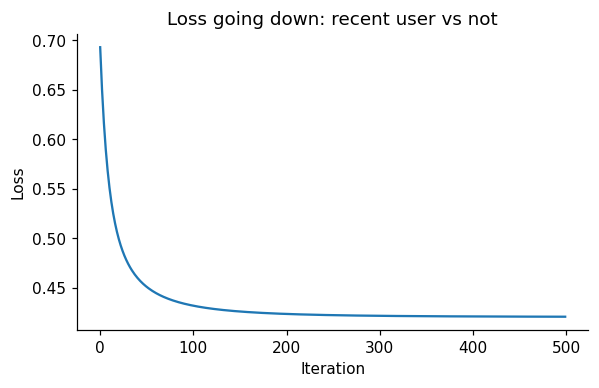

In [14]:
def fit_binary_logistic(X, t, lr = 0.1, l2 = 0.01, n_iter = 1000):
    """train one yes or no logistic regression with batch gradient descent"""

    n, d = X.shape
    w = np.zeros(d)              # one weight per feature, starts at 0
    b = 0.0         # bias (intercept)
    history = []   # loss at every step

    for _ in range(n_iter):
        p = sigmoid(X @ w + b)           # 1) predict the probabilities
        history.append(binary_cross_entropy(t, p) + 0.5 * l2 * np.sum(w ** 2))   # 2) record loss
        error = p - t                  # 3) how wrong are we?
        grad_w = X.T @ error / n + l2 * w # 4) gradient for the weights (+ penalty)
        grad_b = error.mean()             #    gradient for the bias (not penalised)
        w -= lr * grad_w                  # 5) step downhill
        b -= lr * grad_b
        
    return w, b, np.array(history)

# quick test on one binary problem: recent user (class 2) or not?

w_demo, b_demo, h_demo = fit_binary_logistic(Xtr, (ytr == 2).astype(float), lr = 0.1, l2 = 0.01, n_iter = 500)
print("loss at step 0 :", round(h_demo[0], 4), "(= ln 2 = 0.6931)")
print("loss at step 499 :", round(h_demo[-1], 4))
plt.figure(figsize=(6, 3.5))

plt.plot(h_demo)
plt.xlabel("Iteration"); plt.ylabel("Loss"); plt.title("Loss going down: recent user vs not")

plt.show()

The loss at step 0 is 0.6931. After 500 steps it has fallen to 0.4206 so the model has learned something. 

The plot shows this as a curve that falls steeply in the first steps and then flattens. A flat curve means the algorithm has settled and more steps would change almost nothing. If the curve went up or zig zagged then the learning rate would be too large. This test was one yes/no question only: recent user or not?.

## D. One vs rest model

In [15]:
class OneVsRestLogisticRegression:
    """three yes or no logistic regressions (one per class). predict class with the highest probability"""

    def __init__(self, lr = 0.1, l2 = 0.01, n_iter = 1000):
        self.lr, self.l2, self.n_iter = lr, l2, n_iter

    def fit(self, X, y):
        self.classes_ = np.unique(y)

        weights, biases, self.loss_history_ = [], [], []

        for c in self.classes_:
            t = (y == c).astype(float)    # 1 for this class and 0 for all others
            w, b, h = fit_binary_logistic(X, t, self.lr, self.l2, self.n_iter)
            weights.append(w); biases.append(b); self.loss_history_.append(h)

        self.weights_ = np.array(weights)     # shape (3, number of features)
        self.biases_ = np.array(biases)       # shape (3,)
        return self

    def predict_proba(self, X):
        return sigmoid(X @ self.weights_.T + self.biases_)   # shape (n, 3)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

demo = OneVsRestLogisticRegression(lr = 0.1, l2 = 0.01, n_iter = 500).fit(Xtr, ytr)

print("weights_ shape:", demo.weights_.shape, "| biases_ shape:", demo.biases_.shape)

print("Probabilities for first 3 training people:\n", demo.predict_proba(Xtr[:3]).round(3))
print("Predictions:", demo.predict(Xtr[:3]), "| true answers:", ytr[:3])

weights_ shape: (3, 25) | biases_ shape: (3,)
Probabilities for first 3 training people:
 [[0.354 0.153 0.427]
 [0.093 0.421 0.453]
 [0.009 0.08  0.975]]
Predictions: [2 2 2] | true answers: [0 2 2]


The shapes (3, 25) and (3,) confirm that we have three models with 25 weights each. For the first three training people the output shows three probabilities each. 

They do not add up to 1. The first row adds up to 0.934 and the last row to 1.064. This is normal for one vs rest because the three probabilities come from three separate models. We only compare them with each other to find the largest.

The predictions for the three people are 2, 2 and 2 while the true answers are 0, 2 and 2. So two of the three are correct. 

The first person is a miss,  the model gave 0.427 for recent and 0.354 for never although the person never used cannabis. This quick demo model was trained for only 500 steps and is not our final model but it already shows that the task is hard. Personality and demographics do not determine cannabis use and they only give hints.

## E. Metrics and a baseline

In [16]:
def confusion_matrix_np(y_true, y_pred, n_classes = 3):
    cm = np.zeros((n_classes, n_classes), dtype = int)
    np.add.at(cm, (y_true, y_pred), 1)        # rows = truth
    # columns = prediction
    return cm

def evaluate(y_true, y_pred):
    cm = confusion_matrix_np(y_true, y_pred)
    tp = np.diag(cm).astype(float)

    precision = tp / np.maximum(cm.sum(axis = 0), 1)   # of those predicted X, how many were X
    recall    = tp / np.maximum(cm.sum(axis = 1), 1)   # of those truly X, how many we found

    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return {"accuracy": tp.sum() / cm.sum(), "macro_f1": f1.mean(),
            "precision": precision, "recall": recall, "f1": f1, "cm": cm}

def per_class_table(res):
    return pd.DataFrame({"precision": res["precision"], "recall": res["recall"], "f1": res["f1"]},
                        index= LR_CLASSES).round(3)



majority = np.bincount(ytr).argmax()
base = evaluate(yte, np.full_like(yte, majority))

print(f"Baseline (always '{LR_CLASSES[majority]}'): accuracy {base['accuracy']:.3f}, macro-F1 {base['macro_f1']:.3f}")


Baseline (always 'Recent user'): accuracy 0.527, macro-F1 0.230


The baseline reaches an accuracy of 0.527 because 198 of the 376 test people really are recent users. But its macro F1 is only 0.230. The reason is that it finds all recent users (recall 1.0 for that class, F1 of about 0.69) but finds none of the other two classes (F1 of 0 for each). The average of 0.69, 0 and 0 is 0.23. This shows why macro F1 is the fairer score here. The same lazy model looks acceptable in accuracy but terrible in macro F1. Any model we build must clearly beat 0.527 and 0.230.

## F. Validation

In [17]:
def stratified_kfold_indices(y, n_splits = 5, seed = 42):
    rng = np.random.default_rng(seed)

    folds = [[] for _ in range(n_splits)]
    for c in np.unique(y):                         # split each class separately
        idx = np.where(y == c)[0]

        rng.shuffle(idx)
        for k, part in enumerate(np.array_split(idx, n_splits)):
            folds[k].extend(part.tolist())

    return [np.array(sorted(f)) for f in folds]

folds = stratified_kfold_indices(ytr, n_splits = 5, seed = 42)


fold_data = []

for k, val_idx in enumerate(folds):
    fit_idx = np.concatenate([folds[j] for j in range(len(folds)) if j != k])
    pre = clone(preprocessor)                      
    X_fit = pre.fit_transform(Xtr_raw.iloc[fit_idx])
    X_val = pre.transform(Xtr_raw.iloc[val_idx])

    fold_data.append((X_fit, ytr[fit_idx], X_val, ytr[val_idx]))

print("Fold sizes (validation):", [len(f) for f in folds])
print("Class counts in validation fold 0:", np.bincount(ytr[folds[0]]))


Fold sizes (validation): [301, 301, 301, 299, 299]
Class counts in validation fold 0: [ 66  76 159]


The five validation folds have 301, 301, 301, 299 and 299 people which adds up to 1501. In validation fold 0 the class counts are 66, 76 and 159. These are almost exactly one fifth of the training counts 330, 378 and 793 so the stratification worked.

In [18]:
import time

LR_GRID = [0.01, 0.1, 0.5]
L2_GRID = [0.0, 0.001, 0.01, 0.1, 1.0]
N_ITER = 1000

rows = []
start = time.time()

for lr in LR_GRID:
    for l2 in L2_GRID:
        f1s, accs = [], []
        for X_fit, y_fit, X_val, y_val in fold_data:
            model = OneVsRestLogisticRegression(lr = lr, l2 = l2, n_iter = N_ITER).fit(X_fit, y_fit)
            res = evaluate(y_val, model.predict(X_val))

            f1s.append(res["macro_f1"]); accs.append(res["accuracy"])
        rows.append({"lr": lr, "l2": l2, "cv_macro_f1": np.mean(f1s), "cv_macro_f1_std": np.std(f1s),
                     "cv_accuracy": np.mean(accs)})
        
cv_results = pd.DataFrame(rows)

print(f"Grid search took {time.time() - start:.0f} s")

display(cv_results.round(4).sort_values("cv_macro_f1", ascending= False).head(8))

best = cv_results.loc[cv_results["cv_macro_f1"].idxmax()]
BEST_LR, BEST_L2 = float(best["lr"]), float(best["l2"])
print(f"Chosen settings -> lr = {BEST_LR}, l2 = {BEST_L2}  (CV macro-F1 = {best['cv_macro_f1']:.3f} +/- {best['cv_macro_f1_std']:.3f})")


Grid search took 12 s


,lr,l2,cv_macro_f1,cv_macro_f1_std,cv_accuracy
11,0.50,0.001,0.6030,0.0229,0.6802
10,0.50,0.000,0.6029,0.0248,0.6789
5,0.10,0.000,0.6021,0.0221,0.6795
6,0.10,0.001,0.6018,0.0207,0.6796
7,0.10,0.010,0.5922,0.0247,0.6749
12,0.50,0.010,0.5916,0.0210,0.6742
0,0.01,0.000,0.5695,0.0234,0.6616
1,0.01,0.001,0.5695,0.0234,0.6616


Chosen settings -> lr = 0.5, l2 = 0.001  (CV macro-F1 = 0.603 +/- 0.023)




The table lists the 8 best combinations. The best one is a learning rate of 0.5 with l2 of 0.001 with a mean validation macro F1 of 0.603, a standard deviation of 0.023 and an accuracy of about 0.68.

The first three rows have scores of 0.6030, 0.6029 and 0.6021. They differ by less than 0.001 while the fold to fold wobble is about 0.02. So these settings are practically equivalent and the winner is not proven to be better than the others. 

We simply take the top one. The rows further down show that a larger penalty of 0.01 lowers the score slightly (about 0.59) and that a learning rate of 0.01 is clearly worse (about 0.57). With such small steps 1000 iterations are not enough for the model to finish learning.

The figure below shows the grid search result: one line per learning rate with the penalty strength on the x axis and validation macro F1 on the y axis. 

Higher is better. The lines is flat and high for small penalties then dropping sharply at l2 = 1.0. The lr = 0.01 line stays below the others because it learns too slowly. 

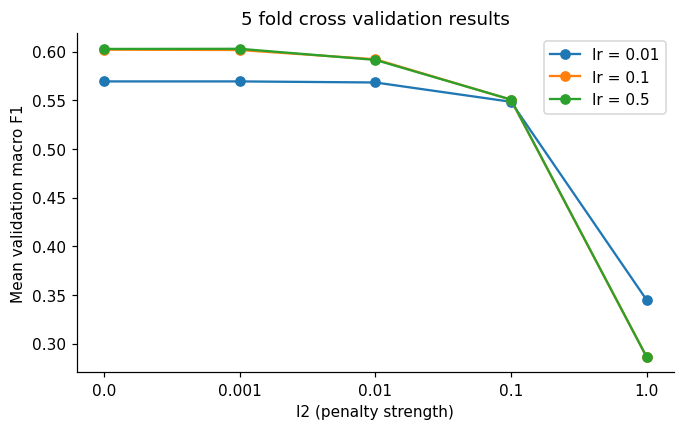

In [19]:
fig, ax = plt.subplots(figsize = (7, 4))

for lr in LR_GRID:
    sub = cv_results[cv_results["lr"] == lr]
    ax.plot(range(len(L2_GRID)), sub["cv_macro_f1"], marker = "o", label = f"lr = {lr}")


ax.set_xticks(range(len(L2_GRID)), [str(v) for v in L2_GRID])

ax.set(xlabel="l2 (penalty strength)", ylabel = "Mean validation macro F1", title = "5 fold cross validation results")
ax.legend()

plt.show()

## G. Training the final model on all training data


Now that the settings are chosen we train once more on all 1501 training rows.

The figure shows the loss curves of the three yes/no models. Each drops and flattens which means gradient descent has converged. The curves end at different heights because some questions are harder than others: "recent user or not?" is easier to answer than "former user or not?".

Training vs validation score (a check for overfitting). We print the score on the training data and compare it with the cross validation score. If training were much higher than validation then the model would be memorising. 

If both are similarly modest, the model is not overfitting. It is limited by how much information 12 demographic/personality columns contain about cannabis use.


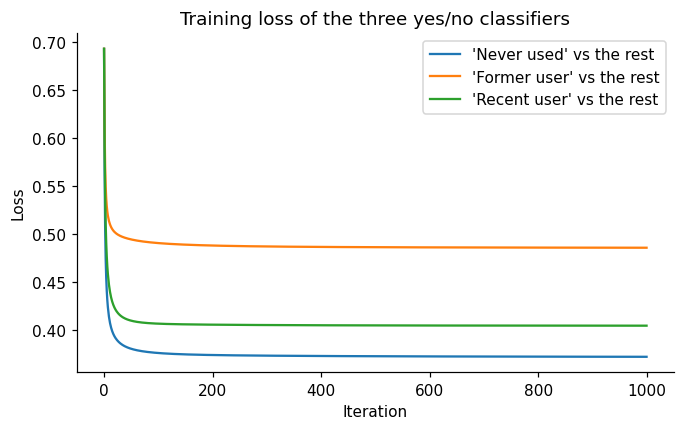

Training accuracy 0.695, training macro F1 0.623
CV (validation) macro F1 0.603


In [20]:
final_model = OneVsRestLogisticRegression(lr = BEST_LR, l2 = BEST_L2, n_iter = N_ITER).fit(Xtr, ytr)

fig, ax = plt.subplots(figsize = (7, 4))

for c, h in zip(LR_CLASSES, final_model.loss_history_):
    ax.plot(h, label = f"'{c}' vs the rest")

ax.set(xlabel = "Iteration", ylabel = "Loss", title = "Training loss of the three yes/no classifiers")
ax.legend()
plt.show()

train_res = evaluate(ytr, final_model.predict(Xtr))
print(f"Training accuracy {train_res['accuracy']:.3f}, training macro F1 {train_res['macro_f1']:.3f}")
print(f"CV (validation) macro F1 {best['cv_macro_f1']:.3f}")


## H. Final evaluation on test set 

TEST accuracy : 0.694   (baseline 0.527)
TEST macro f1 : 0.614   (baseline 0.230)


,precision,recall,f1
Never used,0.608,0.578,0.593
Former user,0.493,0.347,0.407
Recent user,0.783,0.909,0.841


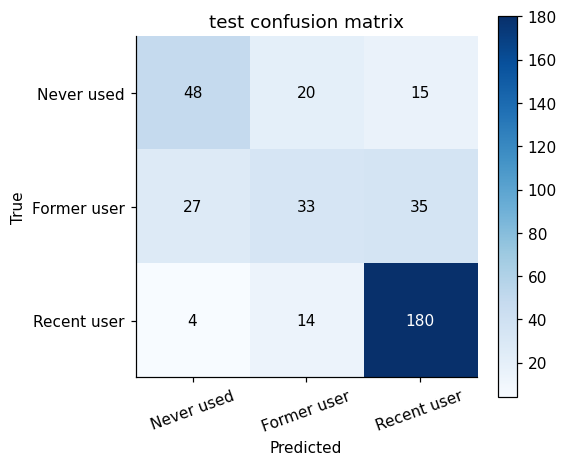

In [21]:
test_pred = final_model.predict(Xte)
test_res = evaluate(yte, test_pred)

print(f"TEST accuracy : {test_res['accuracy']:.3f}   (baseline {base['accuracy']:.3f})")
print(f"TEST macro f1 : {test_res['macro_f1']:.3f}   (baseline {base['macro_f1']:.3f})")
display(per_class_table(test_res))

fig, ax = plt.subplots(figsize = (5, 4.5))
im = ax.imshow(test_res["cm"], cmap = "Blues")
ax.set_xticks(range(3), LR_CLASSES, rotation = 20); ax.set_yticks(range(3), LR_CLASSES)

for i in range(3):

    for j in range(3):
        ax.text(j, i, test_res["cm"][i, j], ha = "center", va = "center",
                color = "white" if test_res["cm"][i, j] > test_res["cm"].max() / 2 else "black")
ax.set(xlabel = "Predicted", ylabel = "True", title = "test confusion matrix")
fig.colorbar(im, ax = ax)


plt.show()

Each row is the truth and each column is the prediction and darker blue means more people. Of the 83 people who never used, 48 were found, 20 were called former users and 15 were called recent users. Of the 95 former users only 33 were found, while 27 were called never used and 35 were called recent users. Of the 198 recent users, 180 were found, 14 were called former users and only 4 were called never used. The correct predictions are 48 + 33 + 180 which is 261/376 giving the accuracy of 0.694.

The model predicted "recent user" for 230 people although only 198 really are recent users and it predicted "former user" for only 67 people although 95 really are. It leans towards the biggest class. The reason is that former users sit between the other two groups. Their personality and demographic profile overlaps with both never users and recent users so a linear model finds it hard to separate them. This is the main weakness of the model and plain accuracy would have hidden it.

## I. What did the model learn?

Each yes/no model has one weight per feature. Because all numeric features are standardised weights are directly comparable: a bigger absolute weight means a stronger influence.

- Positive weight: a higher value of that feature raises the probability of the class.

- Negative weight: it lowers it.

- For one hot columns (like country_UK) the weight says how much belonging to that group shifts the score.

The figure shows the 8 largest magnitude weights for each of the three yes/no models. 

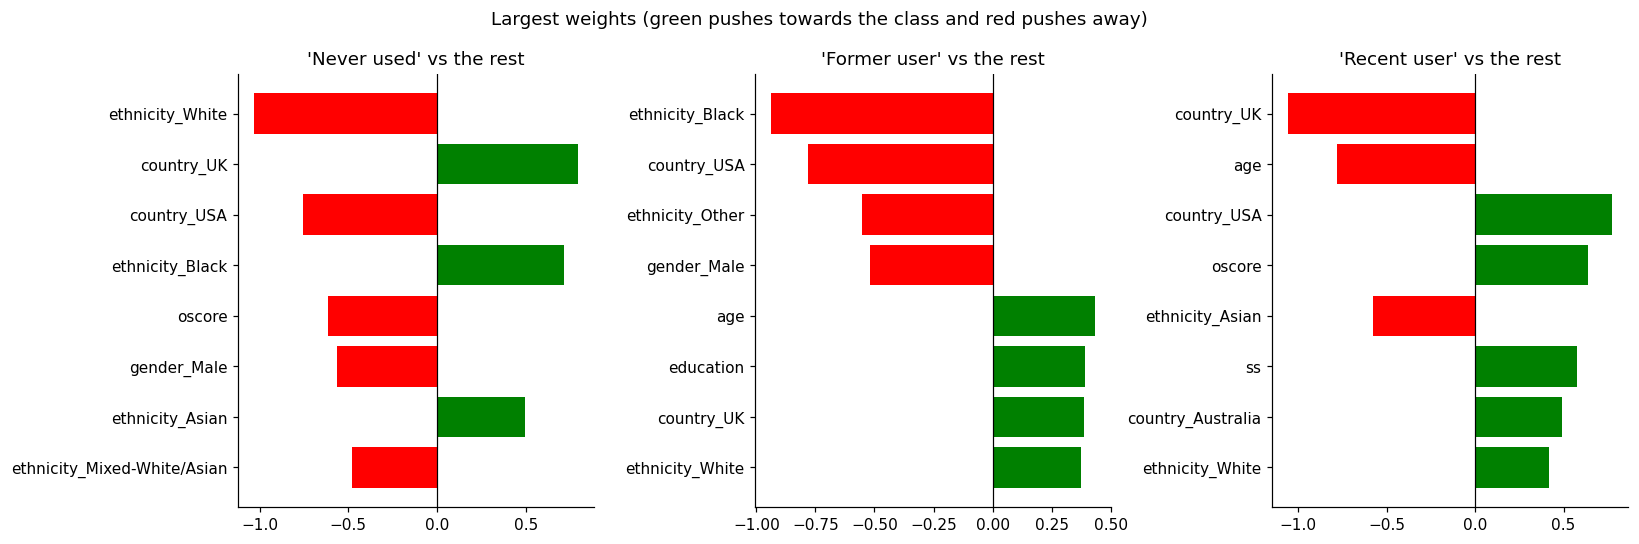

In [22]:
fig, axes = plt.subplots(1, 3, figsize = (15, 5))


for k, ax in enumerate(axes):

    w = final_model.weights_[k] 

    top = np.argsort(np.abs(w))[-8:]         # the 8 biggest weights
     
    ax.barh([FEATURE_NAMES[i] for i in top], w[top], color = ["green" if w[i] > 0 else "red" for i in top])
    ax.axvline(0, color = "black", linewidth = 0.8)
    ax.set_title(f"'{LR_CLASSES[k]}' vs the rest")

fig.suptitle("Largest weights (green pushes towards the class and red pushes away)")
fig.tight_layout()

plt.show()


For "recent user or not" the biggest weights are negative for country_UK (about -1.06) and for age (about -0.78) and positive for country_USA (about 0.77), openness oscore (about 0.64) and sensation seeking ss (about 0.58). In this sample being older makes recent use less likely while higher openness and higher sensation seeking make it more likely.

For "never used or not" the largest weights include ethnicity_White (about -1.03), country_UK (about 0.79), country_USA (about -0.76), openness (about -0.62) and gender_Male (about -0.56). Higher openness and being male make the "never used" answer less likely.

For "former user or not", the largest weights include ethnicity_Black (about -0.94), country_USA (about -0.78), gender_Male (about -0.52), age (about 0.43) and education (about 0.39). Being older makes "former user" more likely which fits with the negative age weight of the recent-user model: older people more often stopped. 


## Summary of logistic regression

- One vs rest logistic regression written from scratch with NumPy, Pandas and Matplotlib. It uses gradient descent with L2 penalty.

- Stratified 5 fold cross validation inside the training set.

- Chosen settings: lr = 0.5, l2 = 0.001, 1000 iterations.

My results (test set, 376 people):

- Accuracy 0.694 and macro F1 0.614.
- The baseline (always “recent user”) gets 0.527 and 0.230.
- Cross validation macro F1 was 0.603 ± 0.023 so the test score matches it.
- “Recent user” is found well (recall 0.91). “Former user” is the hardest class (recall 0.35).


Limitations:

- The model is linear so it cannot capture interactions or curved relationships.

- One vs rest trains three independent models so its probabilities do not add up to 1.

- "Former user" is the weakest class because it overlaps with the other two.

- Quantified age/education are kept as ordered numbers and the test set (376 people) is small so scores have some uncertainty.


# Part 3: Support vector machine (SVM)

We use scikit-learn's `SVC` with an RBF kernel as our second model. It can learn curved decision boundaries, which lets us compare it with the linear logistic regression model. Support vectors are training examples that help define the boundary.

We tune `C` and `gamma`. A larger `C` penalises training errors more strongly. `gamma` controls how local each example's influence is; a large value can produce a fit that is too specific to the training data. We also try balanced class weights because our classes have different sizes.

`SVC` trains one-versus-one classifiers for the three classes. Its decision scores are not probabilities. We select settings by cross-validation macro-F1, which averages the three class F1-scores equally.

Reference: [scikit-learn SVC documentation](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html).

## A. Tune the SVM using the same folds

We reuse the five folds from logistic regression so both models are evaluated on the same validation rows.

The pipeline starts with `Xtr_raw`, before scaling and encoding. It refits preprocessing on the training rows of each fold. Using the already transformed matrix would let validation rows affect those steps.

The grid search tests 32 combinations of `C`, `gamma` and class weighting, then selects the highest mean validation macro-F1. The test set is not used to choose these settings.

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Reuse the logistic regression folds.
svm_cv = [(np.concatenate([folds[j] for j in range(len(folds)) if j != k]), val_idx)
          for k, val_idx in enumerate(folds)]
assert np.array_equal(np.sort(np.concatenate([v for _, v in svm_cv])), np.arange(len(ytr)))
for fit_idx, val_idx in svm_cv:
    assert len(np.intersect1d(fit_idx, val_idx)) == 0

# Fit preprocessing separately within each fold.
svm_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("svc", SVC(kernel="rbf")),
])
svm_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.001, 0.01, 0.1],
    "svc__class_weight": [None, "balanced"],
}
# Balanced weights give smaller classes more weight within each fold.
svm_search = GridSearchCV(
    svm_pipeline, svm_grid, scoring={"macro_f1": "f1_macro", "accuracy": "accuracy"},
    refit="macro_f1", cv=svm_cv, n_jobs=2, return_train_score=True, error_score="raise",
)
svm_start = time.time()
svm_search.fit(Xtr_raw, ytr)
svm_cv_results = pd.DataFrame(svm_search.cv_results_)
svm_cv_results.to_csv(REPORTS / "svm_cv_results.csv", index=False)
svm_best_row = svm_cv_results.iloc[svm_search.best_index_]
print(f"Search: {len(svm_cv_results)} settings, {len(svm_cv)} folds, {time.time()-svm_start:.1f} seconds")
print("Selected parameters:", svm_search.best_params_)
print(f"Validation macro-F1: {svm_search.best_score_:.3f} +/- {svm_best_row['std_test_macro_f1']:.3f}")
display(svm_cv_results[["param_svc__C", "param_svc__gamma", "param_svc__class_weight",
                        "mean_train_macro_f1", "mean_test_macro_f1", "std_test_macro_f1",
                        "mean_test_accuracy"]].sort_values("mean_test_macro_f1", ascending=False).head(10))

Search: 32 settings, 5 folds, 30.0 seconds
Selected parameters: {'svc__C': 100, 'svc__class_weight': None, 'svc__gamma': 0.001}
Validation macro-F1: 0.614 +/- 0.018


,param_svc__C,param_svc__gamma,param_svc__class_weight,mean_train_macro_f1,mean_test_macro_f1,std_test_macro_f1,mean_test_accuracy
25,100.0,0.001,NaN,0.639308,0.614247,0.017604,0.679519
18,10.0,0.01,NaN,0.655934,0.604496,0.021680,0.673521
17,10.0,0.001,NaN,0.615923,0.602602,0.018826,0.672205
29,100.0,0.001,balanced,0.636054,0.599688,0.024583,0.642207
15,1.0,0.1,balanced,0.735803,0.595338,0.021044,0.643572
14,1.0,0.01,balanced,0.621505,0.595312,0.027738,0.641520
4,0.1,scale,balanced,0.632189,0.594532,0.025481,0.646198
22,10.0,0.01,balanced,0.664388,0.594410,0.023558,0.638189
7,0.1,0.1,balanced,0.634866,0.593705,0.023756,0.644878
10,1.0,0.01,NaN,0.618457,0.593383,0.018889,0.666203


## B. Compare training and validation scores

`GridSearchCV` refits the selected pipeline on the full training set. We compare its training macro-F1 with the mean validation score to check the gap in performance.

The fold standard deviation describes variation across the five folds, not a confidence interval. Choosing the highest score from 32 settings may also make that validation score optimistic.

Full-training macro-F1: 0.641
Mean fold-training macro-F1: 0.639
Mean fold-validation macro-F1: 0.614
Support vectors per class: [281 371 290]


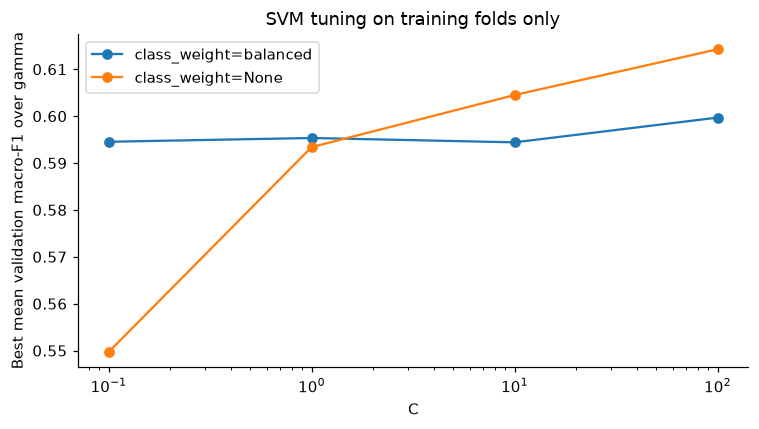

In [24]:
svm_final = svm_search.best_estimator_
svm_train_pred = svm_final.predict(Xtr_raw)
svm_train_f1 = f1_score(ytr, svm_train_pred, average="macro")
print(f"Full-training macro-F1: {svm_train_f1:.3f}")
print(f"Mean fold-training macro-F1: {svm_best_row['mean_train_macro_f1']:.3f}")
print(f"Mean fold-validation macro-F1: {svm_search.best_score_:.3f}")
print("Support vectors per class:", svm_final.named_steps["svc"].n_support_)

fig, ax = plt.subplots(figsize=(7, 4))
for weight, group in svm_cv_results.groupby("param_svc__class_weight", dropna=False):
    label = "None" if pd.isna(weight) else str(weight)
    # Plot the best validation score across gamma values for each C.
    curve = group.groupby("param_svc__C")["mean_test_macro_f1"].max()
    ax.plot(curve.index.astype(float), curve.values, marker="o", label=f"class_weight={label}")
ax.set(xscale="log", xlabel="C", ylabel="Best mean validation macro-F1 over gamma",
       title="SVM tuning on training folds only")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "svm_validation.png", dpi=150)
plt.show()

## C. Evaluate on the test set

We evaluate the selected SVM on the same 376 test respondents as logistic regression. We compare accuracy, macro-F1, per-class scores and confusion matrices.

We save both models' predictions for error analysis and the fitted SVM pipeline for later use.

,precision,recall,f1-score,support
Never used,0.630,0.554,0.590,83.000
Former user,0.488,0.421,0.452,95.000
Recent user,0.787,0.879,0.831,198.000
accuracy,0.691,0.691,0.691,0.691
macro avg,0.635,0.618,0.624,376.000
weighted avg,0.677,0.691,0.682,376.000


,cv_macro_f1,cv_std,test_accuracy,test_macro_f1,former_recall
model,,,,,
Majority baseline,NaN,NaN,0.527,0.230,0.000
Logistic regression (scratch),0.603,0.023,0.694,0.614,0.347
RBF SVM (library),0.614,0.018,0.691,0.624,0.421


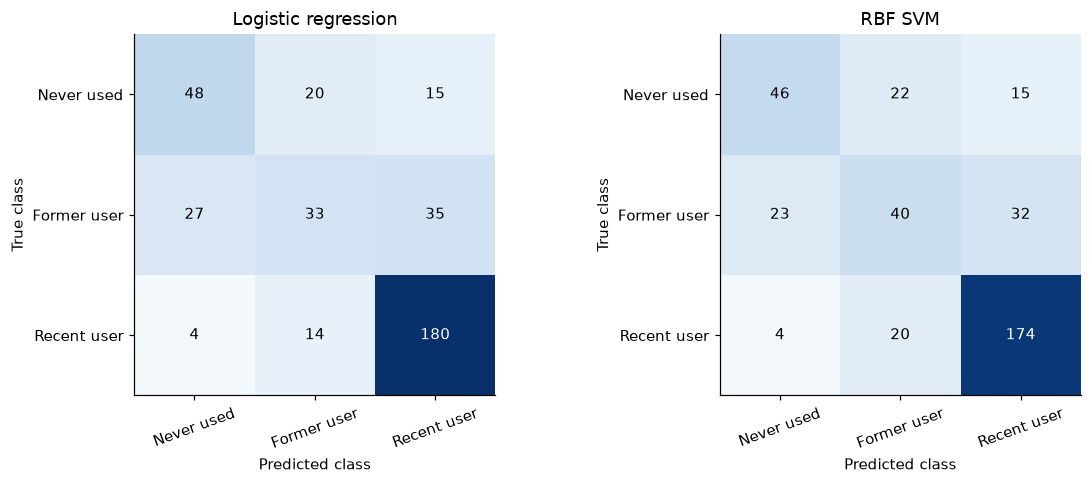

491

In [25]:
Xte_raw = pd.read_csv(OUT / "X_test.csv", index_col="id")
assert Xte_raw.index.equals(yte_s.index)
assert Xte_raw.columns.equals(Xtr_raw.columns)
assert not Xtr_raw.index.isin(Xte_raw.index).any()
# Predict with the settings selected by cross-validation.
svm_test_pred = svm_final.predict(Xte_raw)
svm_test_res = evaluate(yte, svm_test_pred)
assert np.isclose(svm_test_res["macro_f1"], f1_score(yte, svm_test_pred, average="macro"))
assert np.array_equal(svm_test_res["cm"], confusion_matrix(yte, svm_test_pred, labels=[0, 1, 2]))
svm_class_report = pd.DataFrame(classification_report(
    yte, svm_test_pred, labels=[0, 1, 2], target_names=LR_CLASSES,
    output_dict=True, zero_division=0)).T
svm_class_report.to_csv(REPORTS / "svm_test_classification_report.csv")
display(svm_class_report.round(3))

model_comparison = pd.DataFrame([
    {"model": "Majority baseline", "cv_macro_f1": np.nan, "cv_std": np.nan,
     "test_accuracy": base["accuracy"], "test_macro_f1": base["macro_f1"], "former_recall": base["recall"][1]},
    {"model": "Logistic regression (scratch)", "cv_macro_f1": best["cv_macro_f1"],
     "cv_std": best["cv_macro_f1_std"], "test_accuracy": test_res["accuracy"],
     "test_macro_f1": test_res["macro_f1"], "former_recall": test_res["recall"][1]},
    {"model": "RBF SVM (library)", "cv_macro_f1": svm_search.best_score_,
     "cv_std": svm_best_row["std_test_macro_f1"], "test_accuracy": svm_test_res["accuracy"],
     "test_macro_f1": svm_test_res["macro_f1"], "former_recall": svm_test_res["recall"][1]},
]).set_index("model")
model_comparison.to_csv(REPORTS / "model_comparison.csv")
display(model_comparison.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
limit = max(test_res["cm"].max(), svm_test_res["cm"].max())
for ax, title, res in zip(axes, ["Logistic regression", "RBF SVM"], [test_res, svm_test_res]):
    ax.imshow(res["cm"], cmap="Blues", vmin=0, vmax=limit)
    ax.set_xticks(range(3), LR_CLASSES, rotation=20)
    ax.set_yticks(range(3), LR_CLASSES)
    ax.set(xlabel="Predicted class", ylabel="True class", title=title)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, str(res["cm"][i,j]), ha="center", va="center",
                    color="white" if res["cm"][i,j] > limit/2 else "black")
fig.tight_layout()
fig.savefig(FIGURES / "model_confusion_comparison.png", dpi=150)
plt.show()

pd.DataFrame({"actual": yte, "logistic_prediction": test_pred,
              "svm_prediction": svm_test_pred}, index=yte_s.index).to_csv(
                  REPORTS / "model_test_predictions.csv", index_label="id")
# Save preprocessing and the SVM together for later predictions.
joblib.dump(svm_final, OUT / "svm_pipeline.joblib")
svm_metadata = {"best_params": svm_search.best_params_, "selection_metric": "macro_f1",
                "cv_folds": 5, "same_folds_as_algorithm_1": True,
                "cv_macro_f1": float(svm_search.best_score_),
                "cv_std": float(svm_best_row["std_test_macro_f1"]),
                "training_macro_f1": float(svm_train_f1),
                "test_accuracy": float(svm_test_res["accuracy"]),
                "test_macro_f1": float(svm_test_res["macro_f1"]),
                "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                             "numpy": np.__version__, "pandas": pd.__version__}}
(REPORTS / "svm_metadata.json").write_text(json.dumps(svm_metadata, indent=2), encoding="utf-8")

## D. Limitations

The survey uses self-reported answers, and some demographic groups have few respondents. Country and ethnicity may also reflect how participants were recruited, which limits how well the results might apply to other populations. Our target is reported recency of use, not dependence or future use.

The RBF SVM has no single coefficient per feature to interpret as we did for logistic regression. Neither model establishes what causes cannabis use.

## E. SVM results

The selected settings were **C = 100, gamma = 0.001 and no class weighting**. Mean validation macro-F1 was **0.614**, with a fold standard deviation of **0.018**. Logistic regression scored **0.603**, with a standard deviation of **0.023**. SVM's full-training macro-F1 was **0.641**, giving a training-to-validation gap of about **0.027**.

On the test set, SVM scored **0.624 macro-F1**, compared with **0.614** for logistic regression. Accuracy was **69.1% versus 69.4%**: SVM got **260** predictions correct and logistic regression got **261**.

SVM identified **40 of the 95 former users**, compared with **33** for logistic regression. Former-user recall increased from **0.347 to 0.421**, while recall decreased from **0.578 to 0.554** for never users and from **0.909 to 0.879** for recent users.

SVM did slightly better on macro-F1, but the difference is too small to assume it will consistently perform better on new data. `C=100` was the largest C tested, and `gamma=0.001` was the smallest fixed gamma tested. A wider grid might find better settings; we did not extend the search after seeing the test results.

## Export Algorithm 1 for the local demo

Save the fitted scratch model as plain NumPy arrays. The app loads these weights; it does not retrain or replace Algorithm 1 with a library classifier. The shared preprocessing must retain the same feature order.

In [26]:
np.savez(OUT / "logistic_model.npz", weights=final_model.weights_,
         biases=final_model.biases_, classes=final_model.classes_,
         feature_names=np.array(FEATURE_NAMES, dtype=str))
print("Exported scratch logistic regression for the local app.")

Exported scratch logistic regression for the local app.


## Loading and Understanding the Prediction Data

In [1]:
import pandas as pd 

In [8]:
evaluation_df = pd.read_csv("../reports/model_test_predictions.csv")
evaluation_df.head()

,id,actual,logistic_prediction,svm_prediction
0,1047,2,2,2
1,1373,2,2,2
2,1864,2,2,2
3,1738,0,1,1
4,255,2,1,1


In [9]:
evaluation_df.shape

(376, 4)

In this project, we're predicting how recently a respondent has used cannabis. There are three possible classes: never used (Class 0), former user (Class 1), and recent user (Class 2). Both Logistic Regression and SVM were evaluated on the same 376 test respondents.

There are four columns: `id` identifies each respondent, `actual` contains the correct class, `logistic_prediction` contains the class predicted by Logistic Regression, and `svm_prediction` contains the class predicted by SVM.

The idea here is to implement an Error Analysis to check these 4 situations:
- both models correct
- only LR correct
- only SVM correct
- both models incorrect

What is considered correct is when a predicted class is equal to the actual class

## Comparative Error Analysis: Shared and Unique Outcomes

In [11]:
evaluation_df["lr_correct"] = evaluation_df["actual"] == evaluation_df["logistic_prediction"]
evaluation_df["svm_correct"] = evaluation_df["actual"] == evaluation_df["svm_prediction"]


In [17]:
lr_correct_count = evaluation_df["lr_correct"].sum()
print(lr_correct_count)

261


In [18]:
svm_correct_count = evaluation_df["svm_correct"].sum()
print(svm_correct_count)

260


In [22]:
evaluation_df["both_correct"] = (evaluation_df["lr_correct"] & evaluation_df["svm_correct"])

both_correct_count = evaluation_df["both_correct"].sum()
print(both_correct_count)


250


In [25]:
evaluation_df["only_lr_correct"] = (evaluation_df["lr_correct"] & ~evaluation_df["svm_correct"])
only_lr_correct_count = evaluation_df["only_lr_correct"].sum()
print(only_lr_correct_count)

11


In [26]:
evaluation_df["only_svm_correct"] = (~evaluation_df["lr_correct"] & evaluation_df["svm_correct"])
only_svm_correct_count = evaluation_df["only_svm_correct"].sum()
print(only_svm_correct_count)

10


In [27]:
evaluation_df["both_incorrect"] = (~evaluation_df["lr_correct"] & ~evaluation_df["svm_correct"])
both_incorrect_count = evaluation_df["both_incorrect"].sum()
print(both_incorrect_count)

105


In [31]:
error_summary_df = pd.DataFrame({
    "Outcome": ["Both Correct", "Only LR Correct", "Only SVM Correct", "Both Incorrect"],
    "Count": [both_correct_count, only_lr_correct_count, only_svm_correct_count, both_incorrect_count]
})

display(error_summary_df)

,Outcome,Count
0,Both Correct,250
1,Only LR Correct,11
2,Only SVM Correct,10
3,Both Incorrect,105


Both models correctly classified 250 out of 376 respondents, while both incorrectly classified 105 respondents.

The models perform very similarly. Logistic Regression correctly classifies just one more respondent than SVM.

They don't always make the same mistakes. There are 21 respondents where one model is correct and the other is wrong.



## Class-Specific Recall Comparison

In [28]:
evaluation_df["actual"].value_counts()

actual
2    198
1     95
0     83
Name: count, dtype: int64

Class 2 has more than twice as many respondents compared to the other classes => class imbalance

In [29]:
evaluation_df.groupby("actual")["lr_correct"].sum()

actual
0     48
1     33
2    180
Name: lr_correct, dtype: int64

In [ ]:
evaluation_df.groupby("actual")["lr_correct"].mean()    #recall

actual
0    0.578313
1    0.347368
2    0.909091
Name: lr_correct, dtype: float64

The reason why using groupby and mean() returns recall is because the `actual` column contains the correct classes, so we use `.groupby("actual")` to group respondents by their actual class. 

`.mean()` calculates the proportion of correct predictions (`True`) within each class by dividing the number of correct predictions by the total number of respondents in that class. This gives us the recall for each class.

In [33]:
evaluation_df.groupby("actual")["svm_correct"].sum()

actual
0     46
1     40
2    174
Name: svm_correct, dtype: int64

In [36]:
evaluation_df.groupby("actual")["svm_correct"].mean()    #recall

actual
0    0.554217
1    0.421053
2    0.878788
Name: svm_correct, dtype: float64

In [47]:
class_recall_df = (
    evaluation_df.groupby("actual")[["lr_correct","svm_correct"]].mean() * 100
)

display(class_recall_df.round(2))

,lr_correct,svm_correct
actual,,
0,57.83,55.42
1,34.74,42.11
2,90.91,87.88


In [57]:
class_recall_df.rename(columns={
    "lr_correct": "LR Recall (%)",
    "svm_correct": "SVM Recall (%)"
})

,LR Recall (%),SVM Recall (%)
actual,,
0,57.83,55.42
1,34.74,42.11
2,90.91,87.88


LR has a higher recall (better performance) for two classes (0 and 2)

SVM has a higher recall for class 1,  which happens to also be the same class where both models struggle the most

## Class 1 Misclassification Analysis

In [59]:
lr_class1_errors_df = evaluation_df[(evaluation_df["actual"] == 1) & (~evaluation_df["lr_correct"])]

lr_class1_errors_df.shape

(62, 10)

This confirms that Logistic Regression misclassified 62 of the 95 former users

In [60]:
lr_class1_errors_df["logistic_prediction"].value_counts()

logistic_prediction
2    35
0    27
Name: count, dtype: int64

out of the 62 wrong predictions 35 was predicted as recent user and 27 as never used

In [61]:
svm_class1_errors_df = evaluation_df[(evaluation_df["actual"] == 1) & (~evaluation_df["svm_correct"])]

svm_class1_errors_df.shape

(55, 10)

In [62]:
svm_class1_errors_df["svm_prediction"].value_counts()

svm_prediction
2    32
0    23
Name: count, dtype: int64

out of the 55 wrong predictions 32 was predicted as recent users and 23 as never used

Both models misclassify former users as recent users slightly more often than as never users

SVM made 7 fewer incorrect predictions for Class 1 compared to LR, meaning that it correctly identified more former users. This also explains why SVM has a higher recall for Class 1 (42.11%) compared to Logistic Regression (34.74%).

## Shared Error Rates Across Classes

In [63]:
evaluation_df.groupby("actual")["both_incorrect"].sum()

actual
0    33
1    55
2    17
Name: both_incorrect, dtype: int64

Class 0: Both models misclassified 33 never users.

Class 1: Both models misclassified 55 former users.

Class 2: Both models misclassified 17 recent users.

In [68]:
shared_error_df = evaluation_df.groupby("actual")["both_incorrect"].mean()*100
shared_error_df = shared_error_df.to_frame()

shared_error_df = shared_error_df.rename(
    columns={"both_incorrect": "Shared Error Rate (%)"}
).round(2)

display(shared_error_df)

,Shared Error Rate (%)
actual,
0,39.76
1,57.89
2,8.59


Shared error rate represents the percentage of respondents in each class that both models incorrectly classified. This doesn't necessarily mean that both models predicted the exact same wrong class.

Class 1 has the highest shared error rate (57.89%), which tells us that both models struggle with correctly identifying former users.

## Generalization and Potential Overfitting

In [69]:
generalization_df = pd.DataFrame({
    "Model": ["LR", "SVM"],
    "Training Macro F1": [0.623, 0.641],
    "Validation Macro F1": [0.603, 0.614]
})

display(generalization_df)

,Model,Training Macro F1,Validation Macro F1
0,LR,0.623,0.603
1,SVM,0.641,0.614


In [72]:
generalization_df["performance_gap"] =generalization_df["Training Macro F1"] - generalization_df["Validation Macro F1"] 

display(generalization_df)

,Model,Training Macro F1,Validation Macro F1,performance_gap
0,LR,0.623,0.603,0.020
1,SVM,0.641,0.614,0.027


The training and validation Macro F1-scores were obtained from the models' existing training and evaluation results. The validation scores were calculated using 5-fold cross-validation, while the training scores come from the final models trained on the full training dataset.

Both models perform slightly better on training data than during cross-validation

Neither gap is very large, so these results alone don't provide strong evidence of overfitting

So, svm has a larger performance gap, and the difference between models is pretty small, we cannot conclude that either model is overfitting.

## Final Model Comparison and Recommendation

In [74]:
final_comparison_df = pd.DataFrame({
    "Metric": ["Accuracy (%)", "Macro F1", "Class 1 Recall (%)"],
    "Logistic Regression": [69.4, 0.614, 34.7],
    "SVM": [69.1, 0.624, 42.1]
})

display(final_comparison_df.round(2))

,Metric,Logistic Regression,SVM
0,Accuracy (%),69.40,69.10
1,Macro F1,0.61,0.62
2,Class 1 Recall (%),34.70,42.10


I would recommend SVM in this situation because it shows a slightly higher Macro F1-score compared to Logistic Regression. Looking at Macro F1 rather than only accuracy is a better choice in this case because it weighs each class equally when averaging their F1-scores. In our test dataset, Class 2 represents almost 53% of the respondents, meaning that if a model were to predict only Class 2, it would achieve an accuracy of around 53%, even if it failed to identify the other two classes.

SVM also performs better at identifying Class 1, which is the class both models struggle with the most.

In conclusion, even if SVM has a slightly higher Macro F1-score, we cannot be sure to conclude that it performs better overall because we don't know if it would consistently performe better than Logistic Regression on other unseen data. The difference between the models is small, and we haven't performed any statistical tests to check whether this difference is significant.